In [12]:
import os
from pydantic import BaseModel, Field
from IPython.display import Image,display
from typing import TypedDict, Literal, Annotated


from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.messages import SystemMessage, HumanMessage


import operator


from langchain_openai import ChatOpenAI


from langgraph.graph import StateGraph, START, END

In [13]:
#Import models

generator_llm = ChatOpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    model="nvidia/nemotron-3.5-lightning:free"
)

evaluator_llm = ChatOpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    model="nvidia/nemotron-3.5-lightning:free"
)


optimizer_llm = ChatOpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    model="nvidia/nemotron-3.5-lightning:free"
)

parser = StrOutputParser()

In [19]:
# Making the state for the tweet post

class TweetState(TypedDict):
    topic: str
    tweet: str
    tweet_history: Annotated[list[str], operator.add]
    evaluation: Literal["approved", "needs_improvement"]
    evaluation_history: Annotated[list[str], operator.add]
    feedback: str
    iteration: int
    max_iteration: int


# Structured evaluation schema

class EvaluationSchema(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(
        description="Return approved or needs_improvement based on the tweet."
    )
    feedback: str = Field(
        description="Provide one paragraph explaining the tweet's strengths and weaknesses."
    )


structured_evaluator_llm = evaluator_llm.with_structured_output(
    EvaluationSchema
)


# To generate a post

def generatePost(state: TweetState) -> dict:
    messages = [
        SystemMessage(
            content="You are a funny and clever Twitter/X influencer."
        ),
        HumanMessage(
            content=f"""
Write a short, original, and hilarious tweet on the topic:
"{state['topic']}"

Rules:
- Do NOT use question-answer format.
- Maximum 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, everyday English.
"""
        )
    ]

    response = generator_llm.invoke(messages)
    tweet = parser.invoke(response)

    return {
        "tweet": tweet,
        "tweet_history": [tweet]
    }


# To evaluate a post

def evaluatePost(state: TweetState) -> dict:
    messages = [
        SystemMessage(
            content=(
                "You are a ruthless, no-laugh-given Twitter critic. "
                "Evaluate tweets based on humor, originality, "
                "virality, and tweet format."
            )
        ),
        HumanMessage(
            content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use these criteria:
1. Originality: Is it fresh?
2. Humor: Is it genuinely funny?
3. Punchiness: Is it short and memorable?
4. Virality potential: Would people share it?
5. Format: Is it under 280 characters, not Q&A, and not a
   traditional setup-punchline joke?

Automatically reject if:
- It uses question-answer format.
- It exceeds 280 characters.
- It reads like a traditional setup-punchline joke.
- It ends with generic, throwaway, or deflating lines.

Return an evaluation and one paragraph of feedback.
"""
        )
    ]

    response = structured_evaluator_llm.invoke(messages)

    return {
        "evaluation": response.evaluation,
        "feedback": response.feedback,
        "evaluation_history": [response.evaluation]
    }


# Routing function to decide the branch

def evaluationRouting(
    state: TweetState
) -> Literal["approved", "needs_improvement"]:

    if (
        state["evaluation"] == "approved"
        or state["iteration"] >= state["max_iteration"]
    ):
        return "approved"

    return "needs_improvement"


# Post optimizer

def optimizePost(state: TweetState) -> dict:
    messages = [
        SystemMessage(
            content=(
                "You punch up tweets for humor and virality "
                "based on the evaluator's feedback."
            )
        ),
        HumanMessage(
            content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"

Original tweet:
{state['tweet']}

Tweet history:
{state['tweet_history']}

Rewrite it as a short, funny, original tweet.
Avoid Q&A style and traditional setup-punchline jokes.
Stay under 280 characters.
Return only the improved tweet.
"""
        )
    ]

    response = optimizer_llm.invoke(messages)
    tweet = parser.invoke(response)
    iteration = state["iteration"] + 1

    return {
        "tweet": tweet,
        "iteration": iteration,
        "tweet_history": [tweet]
    }


In [20]:
#Making the Graph

graph = StateGraph(TweetState)


# Adding nodes:

graph.add_node('generatePost', generatePost)
graph.add_node('evaluatePost',evaluatePost)
graph.add_node('optimizePost',optimizePost)


# Adding edges

graph.add_edge(START, 'generatePost')
graph.add_edge('generatePost','evaluatePost')
graph.add_conditional_edges('evaluatePost',evaluationRouting,{'approved':END,'needs_improvement':'optimizePost'})
graph.add_edge('optimizePost','evaluatePost')

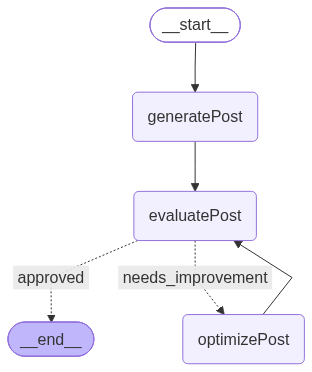

In [21]:
workflow = graph.compile()
display(Image(workflow.get_graph().draw_mermaid_png()))

In [26]:
user_input= {
    "topic": "war",
    "iteration": 0,
    "max_iteration": 3,
    "tweet_history": [],
    "evaluation_history": []
}

result = workflow.invoke(user_input)

print(result)


{'topic': 'war', 'tweet': 'War is what happens when two egos with bad WiFi fight over a group chat. No winners. Just expensive therapy and a bunch of read receipts. 📱💸', 'tweet_history': ['War is what happens when two egos with bad WiFi fight over a group chat. No winners. Just expensive therapy and a bunch of read receipts. 📱💸'], 'evaluation': 'approved', 'evaluation_history': ['approved'], 'feedback': "This tweet nails the modern absurdity of digital conflict with surprising economy and self-awareness. The metaphor of egos duking it out over bad WiFi in a group chat is instantly recognizable, and the pivot to 'expensive therapy and read receipts' lands as both punchline and social commentary without feeling like a forced joke. It’s concise, visually punchy thanks to the emojis, and shareable enough to trend in any group chat that’s ever seen a passive-aggressive Tuesday. If there’s a slight flaw, it’s that the premise skirts close to relatable observation rather than outright absurdi

In [27]:
print(f"Final tweet = \n {result['tweet']}")
print(f"Total Inerations = \n {result['iteration']}")

print(f"Evaluation = \n {result['evaluation']}")
print(f"Evaluation History = \n {result['evaluation_history']}")

print("Tweet history = \n", result["tweet_history"])

Final tweet = 
 War is what happens when two egos with bad WiFi fight over a group chat. No winners. Just expensive therapy and a bunch of read receipts. 📱💸
Total Inerations = 
 0
Evaluation = 
 approved
Evaluation History = 
 ['approved']
Tweet history = 
 ['War is what happens when two egos with bad WiFi fight over a group chat. No winners. Just expensive therapy and a bunch of read receipts. 📱💸']
